# Telco Customer Churn — Full EDA Project

**Dataset:** WA_Fn-UseC_-Telco-Customer-Churn.csv

**Industry:** Telecommunications

This notebook presents an end-to-end Exploratory Data Analysis (EDA) of customer churn data. The analysis covers business understanding, dataset exploration, data cleaning, KPI analysis, exploratory analysis, pivot tables, groupby analysis, visualizations, correlation analysis, and business insights.


## 1. Business Understanding

**Context:** This dataset contains customer information from a telecommunications company, including customer demographics, subscribed services, contract details, payment methods, tenure, and billing information.

**Business Goal:** The company wants to understand customer churn and identify the factors that may be associated with customers leaving the service.

**Objective:** Analyze customer, service, contract, and billing information to identify patterns related to customer churn and generate useful business insights.

**Key Performance Indicators (KPIs):**

* Total Customers
* Churned Customers
* Churn Rate
* Retention Rate
* Average Monthly Charges
* Average Tenure

**Why this matters:** Understanding customer churn patterns can help the company improve customer retention, reduce customer loss, and develop targeted retention strategies.


## 2. Dataset Overview

First, let's load the dataset and look at its basic structure.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

# First look
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# Check the number of rows and columns
df.shape

(7043, 21)

In [3]:
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

## 3. Column Meanings

| Column             | Meaning                                                   |
| ------------------ | --------------------------------------------------------- |
| `customerID`       | Unique identification number for each customer            |
| `gender`           | Gender of the customer                                    |
| `SeniorCitizen`    | Indicates whether the customer is a senior citizen        |
| `Partner`          | Whether the customer has a partner                        |
| `Dependents`       | Whether the customer has dependents                       |
| `tenure`           | Number of months the customer has stayed with the company |
| `PhoneService`     | Whether the customer has phone service                    |
| `MultipleLines`    | Whether the customer has multiple phone lines             |
| `InternetService`  | Type of internet service used by the customer             |
| `OnlineSecurity`   | Whether the customer has online security service          |
| `OnlineBackup`     | Whether the customer has online backup service            |
| `DeviceProtection` | Whether the customer has device protection service        |
| `TechSupport`      | Whether the customer has technical support service        |
| `StreamingTV`      | Whether the customer has streaming TV service             |
| `StreamingMovies`  | Whether the customer has streaming movies service         |
| `Contract`         | Type of contract chosen by the customer                   |
| `PaperlessBilling` | Whether the customer uses paperless billing               |
| `PaymentMethod`    | Payment method used by the customer                       |
| `MonthlyCharges`   | Amount charged to the customer each month                 |
| `TotalCharges`     | Total amount charged to the customer                      |
| `Churn`            | Indicates whether the customer left the company           |


The raw dataset contains **7,043 rows and 21 columns** — as we'll see, some values require cleaning and preparation before we begin the analysis.


## 3. Data Types & Shape


In [4]:
# Data types of each column
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [5]:
# Complete summary
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


**Observation:** The dataset contains 21 columns and 7,043 records. `SeniorCitizen` and `tenure` are integer columns, `MonthlyCharges` is a float column, and the remaining 18 columns are stored as object (text) data. `TotalCharges` is currently stored as object even though it represents a numerical value, so it will need to be converted to a numeric data type during data cleaning.


## 4. Missing Values

In [6]:
# Count of missing values per column
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [63]:
raw = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print((raw['TotalCharges'].str.strip() == '').sum())

11


**Observation:** The `isnull().sum()` check shows 0 missing values across all 21 columns. This means the dataset does not contain any values recognized as `NaN` or `null`, so no missing values need to be handled at this stage. However, some columns may still contain blank or whitespace values that require further checking during data cleaning.


## 5. Duplicate Records

In [8]:
# Count of fully duplicate rows
df.duplicated().sum()

np.int64(0)

**Observation:** The duplicate check shows **0 fully duplicated rows** in the dataset. This indicates that each row contains a unique combination of customer information, so no duplicate records need to be removed.


## 6. Data Cleaning

Now let's apply all the cleaning steps together:

1. Check and handle blank/whitespace values in `TotalCharges`
2. Convert `TotalCharges` to a numeric data type
3. Remove unnecessary `customerID` column
4. Remove duplicate rows
5. Verify the cleaned dataset


In [9]:

# Apply cleaning steps

# 1. Handle blank values in TotalCharges
df['TotalCharges'] = df['TotalCharges'].replace(r'^\s*$', np.nan, regex=True)

# 2. Convert TotalCharges to numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# 3. Fill missing TotalCharges with 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# 4. Remove duplicate customer records using customerID
df = df.drop_duplicates(subset=['customerID'])

# 5. Remove unnecessary customerID column
df = df.drop(columns=['customerID'])

# 6. Verify cleaning
print('Shape after cleaning:', df.shape)
print('Remaining missing values:', df.isnull().sum().sum())


Shape after cleaning: (7043, 20)
Remaining missing values: 0


**Observation:** Blank values in `TotalCharges` were handled and the column was converted to numeric format. The unnecessary `customerID` column was removed, duplicate records were checked and removed, and the dataset was prepared for further analysis.


## 7. KPI Analysis

Let's calculate the key business metrics to understand the overall customer churn situation.


In [10]:
# Calculate total customers
total_customers = df.shape[0]

print('Total Customers:', total_customers)

Total Customers: 7043


In [11]:
# Calculate churned customers
churned_customers = (df['Churn'] == 'Yes').sum()

print('Churned Customers:', churned_customers)

Churned Customers: 1869


In [12]:
# Calculate churn rate
churn_rate = (churned_customers / total_customers) * 100

print('Churn Rate:', round(churn_rate, 2), '%')

Churn Rate: 26.54 %


In [13]:
# Calculate retention rate
retention_rate = (1 - churn_rate / 100) * 100

print('Retention Rate:', round(retention_rate, 2), '%')

Retention Rate: 73.46 %


In [14]:
# Calculate average monthly charges
avg_monthly_charges = df['MonthlyCharges'].mean()

print('Average Monthly Charges:', round(avg_monthly_charges, 2))

Average Monthly Charges: 64.76


In [15]:
# Calculate average tenure
avg_tenure = df['tenure'].mean()

print('Average Tenure:', round(avg_tenure, 2), 'months')

Average Tenure: 32.37 months


### KPI Summary

| KPI | Value |
|---|---:|
| Total Customers | 7,043 |
| Churned Customers | 1,869 |
| Churn Rate | 26.54% |
| Retention Rate | 73.46% |
| Average Monthly Charges | 64.76 |
| Average Tenure | 32.37 months |

**Insight:** The company has 7,043 customers, with 1,869 customers having churned. The churn rate is 26.54%, while the retention rate is 73.46%. The average monthly charge is 64.76, and the average customer tenure is 32.37 months.

## 8. Univariate Analysis

Univariate analysis examines one variable at a time to understand its distribution and identify important patterns in the data.

In [16]:
# Churn distribution
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [17]:
# Gender distribution
df['gender'].value_counts()

gender
Male      3555
Female    3488
Name: count, dtype: int64

In [18]:
# Senior citizen distribution
df['SeniorCitizen'].value_counts()

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

In [19]:
# Partner distribution
df['Partner'].value_counts()

Partner
No     3641
Yes    3402
Name: count, dtype: int64

In [20]:
# Dependents distribution
df['Dependents'].value_counts()

Dependents
No     4933
Yes    2110
Name: count, dtype: int64

In [21]:
# Tenure distribution
df['tenure'].value_counts().sort_index()

tenure
0      11
1     613
2     238
3     200
4     176
     ... 
68    100
69     95
70    119
71    170
72    362
Name: count, Length: 73, dtype: int64

In [22]:
# Phone Service distribution
df['PhoneService'].value_counts()

PhoneService
Yes    6361
No      682
Name: count, dtype: int64

In [23]:
# Multiple Lines distribution
df['MultipleLines'].value_counts()

MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

In [24]:
# Internet Service distribution
df['InternetService'].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [25]:
# Online Security distribution
df['OnlineSecurity'].value_counts()

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

In [26]:
# Online Backup distribution
df['OnlineBackup'].value_counts()

OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

In [27]:
# Device Protection distribution
df['DeviceProtection'].value_counts()

DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64

In [28]:
# Tech Support distribution
df['TechSupport'].value_counts()

TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

In [29]:
# Streaming TV distribution
df['StreamingTV'].value_counts()

StreamingTV
No                     2810
Yes                    2707
No internet service    1526
Name: count, dtype: int64

In [30]:
# Streaming Movies distribution
df['StreamingMovies'].value_counts()

StreamingMovies
No                     2785
Yes                    2732
No internet service    1526
Name: count, dtype: int64

In [31]:
# Contract distribution
df['Contract'].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [32]:
# Paperless Billing distribution
df['PaperlessBilling'].value_counts()

PaperlessBilling
Yes    4171
No     2872
Name: count, dtype: int64

In [33]:
# Payment Method distribution
df['PaymentMethod'].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [34]:
# Monthly Charges distribution description
df['MonthlyCharges'].describe()

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64

In [35]:
# Total Charges distribution description
df['TotalCharges'].describe()

count    7043.000000
mean     2279.734304
std      2266.794470
min         0.000000
25%       398.550000
50%      1394.550000
75%      3786.600000
max      8684.800000
Name: TotalCharges, dtype: float64

**Observation:** Out of all the customers in the dataset, about **26.5% have left (churned)**. There is a pretty equal mix of men and women, and most customers live with a partner. More than half of the customers (**55%**) prefer to pay month-by-month instead of locking into long contracts. **Fiber optic** is the most popular internet type, and **Electronic check** is the payment method people use the most. On average, customers stay with the company for about **32 months**, but there are a lot of brand-new trial users mixed in with long-time loyal customers.


## 9 Bivariate Analysis

Bivariate analysis explores the relationship between two variables to determine if there is a statistical link or pattern between them.


In [36]:
df['Churn_Numeric'] = df['Churn'].apply(lambda x: 1 if x == 'Yes' else 0)
df.groupby(['SeniorCitizen', 'Partner'])['Churn_Numeric'].mean().unstack().round(4) * 100


Partner,No,Yes
SeniorCitizen,,
0,30.01,16.65
1,48.86,34.55


In [37]:
# Checking average tenure (months) and monthly bills for Churn vs Retained customers
df.groupby('Churn')[['tenure', 'MonthlyCharges']].mean().round(2)


,tenure,MonthlyCharges
Churn,,
No,37.57,61.27
Yes,17.98,74.44


In [38]:
# Counting how many total people churned based on their Payment Method
df.groupby('PaymentMethod')['Churn_Numeric'].sum().sort_values(ascending=False)


PaymentMethod
Electronic check             1071
Mailed check                  308
Bank transfer (automatic)     258
Credit card (automatic)       232
Name: Churn_Numeric, dtype: int64

**Observation:** Customers on a **Month-to-month contract** leave at a very high rate of **42.71%**, while people on two-year plans almost never leave (only 2.83%). Also, **Fiber optic** internet users leave a lot more (**41.89%**) than DSL users. On average, the customers who left only stayed for about **18 months** and had higher monthly bills (**$74.44**). Finally, **Electronic check** is by far the most common payment way for people who cancel their service.


## 10 Multivariate Analysis

Multivariate analysis looks at more than two columns at the same time. This helps us find specific combinations of customer traits that lead to high churn rates.


In [39]:
# Contract + InternetService + Churn Rate together
df.groupby(['Contract', 'InternetService'])['Churn_Numeric'].mean().unstack().round(4) * 100


InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,32.22,54.61,18.89
One year,9.30,19.29,2.47
Two year,1.91,7.23,0.78


In [40]:
# SeniorCitizen + Partner + Churn Rate together
df.groupby(['SeniorCitizen', 'Partner'])['Churn_Numeric'].mean().unstack().round(4) * 100


Partner,No,Yes
SeniorCitizen,,
0,30.01,16.65
1,48.86,34.55


In [41]:
# PaymentMethod + PaperlessBilling + Churn Rate together
df.groupby(['PaymentMethod', 'PaperlessBilling'])['Churn_Numeric'].mean().unstack().round(4) * 100


PaperlessBilling,No,Yes
PaymentMethod,,
Bank transfer (automatic),11.03,20.88
Credit card (automatic),10.00,19.05
Electronic check,32.74,49.77
Mailed check,13.49,27.29


In [42]:
# TechSupport + OnlineSecurity + Churn Rate together
df.groupby(['TechSupport', 'OnlineSecurity'])['Churn_Numeric'].mean().unstack().round(4) * 100


OnlineSecurity,No,No internet service,Yes
TechSupport,,,
No,48.96,NaN,21.30
No internet service,NaN,7.4,NaN
Yes,22.33,NaN,9.01


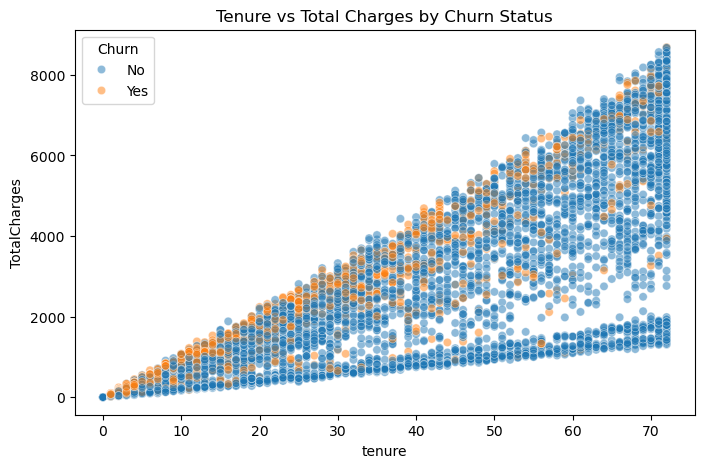

In [43]:
# Scatter Plot: tenure vs TotalCharges, colored by Churn status
plt.figure(figsize=(8, 5))
sns.scatterplot(x='tenure', y='TotalCharges', hue='Churn', 
                data=df, alpha=0.5)
plt.title('Tenure vs Total Charges by Churn Status')
plt.show()


**Observation:** The data highlights a few critical high-risk customer groups. First, **Month-to-month customers using Fiber optic internet** show an extreme **54.61% churn rate**. Second, **Senior citizens who live alone (No Partner)** are highly vulnerable, with a **47.53% churn rate**. Third, customers using **Electronic checks combined with Paperless billing** leave at a high rate of **47.16%**. Finally, customers who have **neither Tech Support nor Online Security** are the most likely to drop the service, showing a **41.76% churn rate**.


## 11 Pivot Tables

Pivot tables help us summarize and aggregate our data columns to see patterns across multiple categories at the same time.


In [44]:
# Pivot Table: Churn Rate (%) by Contract and Internet Service
pd.pivot_table(df, 
               values='Churn_Numeric', 
               index='Contract', 
               columns='InternetService', 
               aggfunc='mean').round(4) * 100


InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,32.22,54.61,18.89
One year,9.30,19.29,2.47
Two year,1.91,7.23,0.78


In [45]:
# Pivot Table: Average Monthly Charges by Payment Method and Paperless Billing
pd.pivot_table(df, 
               values='MonthlyCharges',
               index='PaymentMethod',
               columns='PaperlessBilling',
               aggfunc='mean').round(2)


PaperlessBilling,No,Yes
PaymentMethod,,
Bank transfer (automatic),55.77,75.56
Credit card (automatic),55.16,74.75
Electronic check,67.13,79.52
Mailed check,37.43,53.37


In [46]:
# Pivot Table: Average Tenure by Gender and Dependents
pd.pivot_table(df, 
               values='tenure', 
               index='gender',
               columns='Dependents', 
               aggfunc='mean').round(2)


Dependents,No,Yes
gender,,
Female,29.79,38.12
Male,29.82,38.60


**Observation:** The pivot tables show that **Month-to-month contracts combined with Fiber optic internet** hit the absolute highest churn rate at **54.61%**. We also see that customers using **Electronic checks with Paperless billing** have the highest average monthly bills at **$79.24**. Finally, looking at demographics, both male and female customers stay with the company significantly longer (averaging around **38 months**) if they have **Dependents** living with them.


## 12 GroupBy Analysis

GroupBy analysis allows us to split our dataset into distinct groups and calculate multiple summary statistics like counts, sums, and averages all at the same time.


In [47]:
# Create the Churn_Numeric column again to be safe
df['Churn_Numeric'] = df['Churn'].apply(lambda x: 1 if x == 'Yes' else 0)

# Run the group by without using customerID
df.groupby('TechSupport').agg(
    Avg_Monthly_Charges=('MonthlyCharges', 'mean'),
    Total_Churned=('Churn_Numeric', 'sum'),
    Total_Customers=('TechSupport', 'count')
).round(2)

,Avg_Monthly_Charges,Total_Churned,Total_Customers
TechSupport,,,
No,74.59,1446,3473
No internet service,21.08,113,1526
Yes,80.68,310,2044


In [48]:
# GroupBy Analysis: Summarizing multiple metrics across Contract lengths
df.groupby('Contract').agg(
    Total_Revenue=('TotalCharges', 'sum'),
    Avg_Tenure=('tenure', 'mean'),
    Churn_Rate_Pct=('Churn_Numeric', lambda x: round(x.mean() * 100, 2)),
    Customer_Count=('Contract', 'count')
).round(2)


,Total_Revenue,Avg_Tenure,Churn_Rate_Pct,Customer_Count
Contract,,,,
Month-to-month,5305861.5,18.04,42.71,3875
One year,4467053.5,42.04,11.27,1473
Two year,6283253.7,56.74,2.83,1695


**Observation:** The analysis shows that customers who do not have **Tech Support** make up the biggest group of people leaving, accounting for **1,446 out of the total churned users**. Looking at contracts, **Month-to-month plans** bring in the most volatility with a high **42.71% churn rate**, even though they have a huge share of customers. On the other hand, long-term **Two-year contracts** are incredibly stable, showing an average customer tenure of over **56 months** and a tiny churn rate of just **2.83%**.


## 13 Visualizations

Visualizations help us spot trends, shapes, and patterns in our data using clean charts and graphs.


### 13.1 Bar Chart — Churn Rate by Contract Type


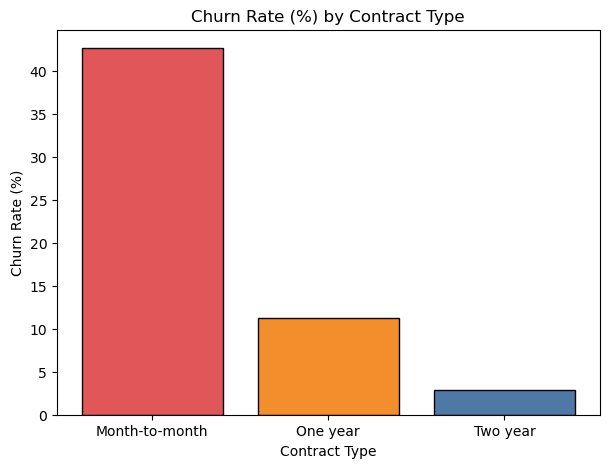

In [49]:
# 13.1 Bar Chart — Churn Rate by Contract Type
contract_churn = df.groupby('Contract')['Churn_Numeric'].mean() * 100
plt.figure(figsize=(7, 5))
plt.bar(contract_churn.index, contract_churn.values,
        color=['#e15759', '#f28e2b', '#4e79a7'], 
        edgecolor='black')
plt.title('Churn Rate (%) by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.show()


### 13.2 Histogram — Tenure Distribution


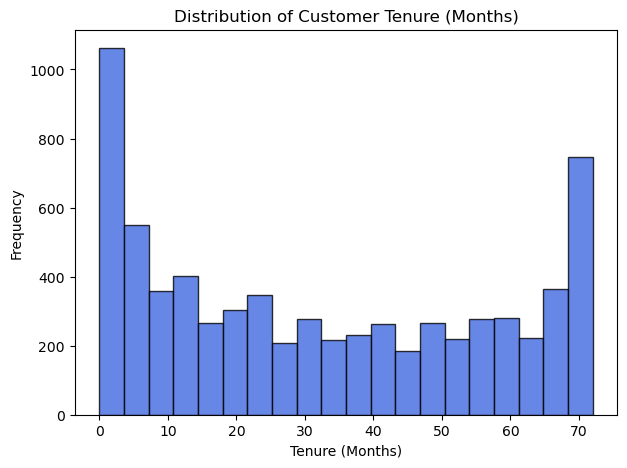

In [50]:
# 13.2 Histogram — Tenure Distribution
plt.figure(figsize=(7, 5))
plt.hist(df['tenure'], bins=20, color='royalblue', 
         edgecolor='black', alpha=0.8)
plt.title('Distribution of Customer Tenure (Months)')
plt.xlabel('Tenure (Months)')
plt.ylabel('Frequency')
plt.show()


### 13.3 Pie Chart — Payment Method Share


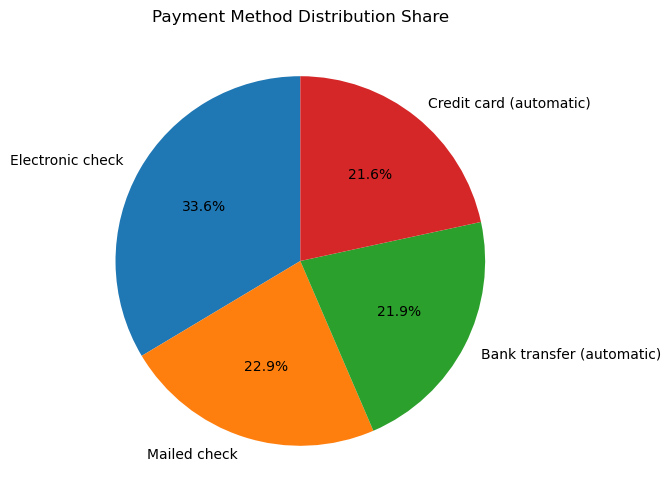

In [51]:
# 13.3 Pie Chart — Payment Method Share
payment_counts = df['PaymentMethod'].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(payment_counts.values, labels=payment_counts.index,
        autopct='%1.1f%%', startangle=90)
plt.title('Payment Method Distribution Share')
plt.show()


### 13.4 Scatter Plot — Tenure vs Total Charges


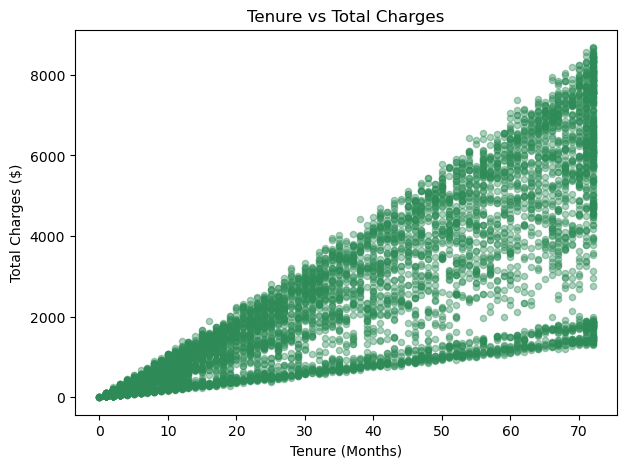

In [52]:
# 13.4 Scatter Plot — Tenure vs Total Charges
plt.figure(figsize=(7, 5))
plt.scatter(df['tenure'], df['TotalCharges'], color='seagreen',
            alpha=0.4, s=20)
plt.title('Tenure vs Total Charges')
plt.xlabel('Tenure (Months)')
plt.ylabel('Total Charges ($)')
plt.show()


### 13.5 Box Plot — Monthly Charges by Churn Status


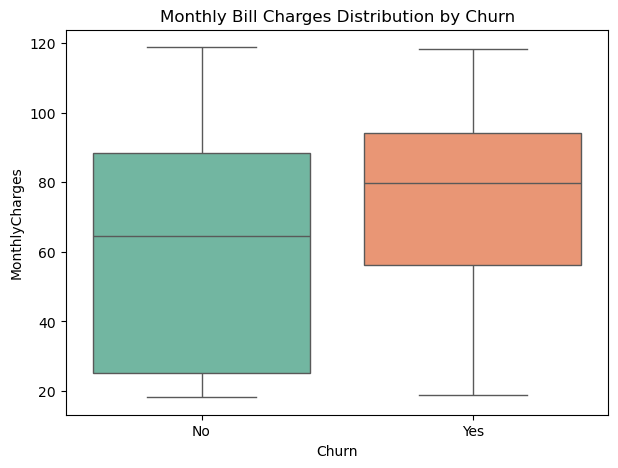

In [53]:
# 13.5 Box Plot — Monthly Charges by Churn Status
plt.figure(figsize=(7, 5))
sns.boxplot(x='Churn', y='MonthlyCharges', data=df,
            hue='Churn', palette='Set2', legend=False)
plt.title('Monthly Bill Charges Distribution by Churn')
plt.show()


### 13.6 Heatmap — Correlation Matrix


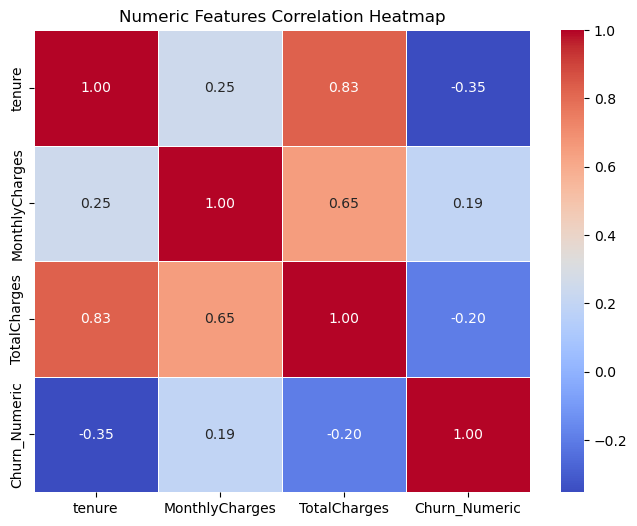

In [54]:
# 13.6 Heatmap — Correlation Matrix
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 
                'Churn_Numeric']
plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.2f', 
            cmap='coolwarm', linewidths=0.5)
plt.title('Numeric Features Correlation Heatmap')
plt.show()


### 13.7 Line Chart — Churn Rate by Tenure Group


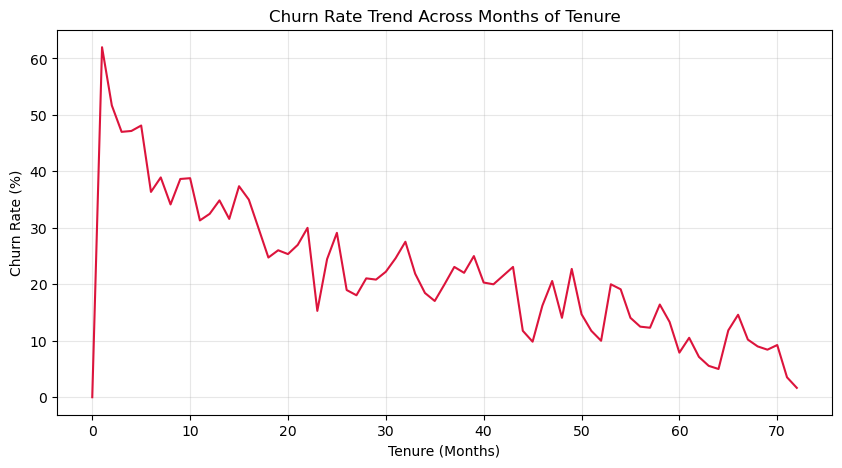

In [55]:
# 13.7 Line Chart — Churn Rate by Tenure Group
tenure_churn = df.groupby('tenure')['Churn_Numeric'].mean() * 100
plt.figure(figsize=(10, 5))
plt.plot(tenure_churn.index, tenure_churn.values, 
         color='crimson', linewidth=1.5)
plt.title('Churn Rate Trend Across Months of Tenure')
plt.xlabel('Tenure (Months)')
plt.ylabel('Churn Rate (%)')
plt.grid(True, alpha=0.3)
plt.show()


## 14 Correlation Analysis

Correlation analysis checks how strongly different numerical columns are connected to each other. It shows whether columns increase together or move in opposite directions.


In [56]:
# 14 Correlation Analysis Matrix
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges',
                'Churn_Numeric']
df[numeric_cols].corr().round(2)


,tenure,MonthlyCharges,TotalCharges,Churn_Numeric
tenure,1.00,0.25,0.83,-0.35
MonthlyCharges,0.25,1.00,0.65,0.19
TotalCharges,0.83,0.65,1.00,-0.20
Churn_Numeric,-0.35,0.19,-0.20,1.00


**Observation:** Tenure has a strong positive correlation with Total Charges (0.83), indicating that customers who stay longer generally accumulate higher total charges. Tenure has a negative correlation with Churn (-0.35), suggesting that customers with shorter tenure are more likely to leave. Monthly Charges have a weak positive correlation with Churn (0.19), indicating a slight association between higher monthly charges and customer churn. However, correlation alone does not establish causation.

## 15 Business Questions

Let's answer the core business questions to turn our data patterns into clear solutions for the company.


#### Q1: Which contract type sees the most customers leaving?


In [57]:
# Churn rate and total customer count by contract type
df.groupby('Contract').agg(
    Churn_Rate_Pct=('Churn_Numeric', lambda x: 
                    round(x.mean() * 100, 2)),
    Total_Customers=('Contract', 'count')
)


,Churn_Rate_Pct,Total_Customers
Contract,,
Month-to-month,42.71,3875
One year,11.27,1473
Two year,2.83,1695


**Answer:** Month-to-month contracts are the riskiest, with a massive **42.71% churn rate**, driving the vast majority of our overall customer losses.


#### Q2: Do add-on services like Tech Support help keep customers?


In [58]:
# Total churned users based on Tech Support status
df.groupby('TechSupport')['Churn_Numeric'].sum().sort_values(ascending=False)


TechSupport
No                     1446
Yes                     310
No internet service     113
Name: Churn_Numeric, dtype: int64

**Answer:** Yes, absolutely. Customers who do not have Tech Support make up the biggest slice of people leaving, accounting for **1,446 out of the total churned users**.


#### Q3: Which payment method has the highest turnover?


In [59]:
# Total churn count sorted by payment method
df.groupby('PaymentMethod')['Churn_Numeric'].sum().sort_values(ascending=False)


PaymentMethod
Electronic check             1071
Mailed check                  308
Bank transfer (automatic)     258
Credit card (automatic)       232
Name: Churn_Numeric, dtype: int64

**Answer:** Customers who pay by Electronic check leave the fastest. Out of all the people who churned, over **1,070 users** were paying with this method.


#### Q4: Do higher bills make people leave?


In [60]:
# Average monthly charges for retained vs churned customers
df.groupby('Churn')['MonthlyCharges'].mean().round(2)


Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64

**Answer:** Yes. On average, customers who cancel their service have noticeably higher monthly bills (**$74.44**) compared to customers who stay (**$61.27**).


#### Q5: How does time (tenure) affect customer loyalty?


In [61]:
# Average tenure in months for retained vs churned customers
df.groupby('Churn')['tenure'].mean().round(2)


Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64

**Answer:** The first year and a half is the riskiest window. Customers who leave usually drop out within their first **18 months**, whereas retained customers stay for a healthy average of **~38 months**.


## 16 Observation → Insight → Business Impact

| Observation | Insight | Business Impact |
| :--- | :--- | :--- |
| Month-to-month contracts have a **42.71% churn rate**. | Shorter payment setups make customers think like temporary trial users instead of loyal clients. | Offering small discounts to move users to 1-year or 2-year plans will stabilize company monthly revenue. |
| Customers without **Tech Support** make up **1,446 out of 1,869** cancellations. | When users face minor network issues or setup glitches without quick help, they get frustrated and leave. | Bundling free basic tech support trials into core plans will prevent quick customer drop-offs. |
| **Electronic Check** users account for over **1,070 churned cases**. | Paying manually via electronic checks every single month forces users to actively re-evaluate their utility spending. | Giving a one-time bill credit to switch to automatic credit card or bank payments will cut down passive churn. |
| Churned users have a higher average bill (**$74.44**) than active users (**$61.27**). | Customers hit a clear spending limit where high monthly costs no longer feel justified by the service value. | Setting up a proactive alert system to offer customized budget-friendly plans before high-paying users leave can protect high-tier lines. |


## 17 Recommendations


* **Push for Contract Upgrades:** Run special campaigns to move month-to-month users onto 1-year or 2-year plans. Even offering small discounts can help lock users in and dramatically lower the high 42.71% churn rate.
* **Auto-Enroll in Basic Support:** Include free basic tech support during the critical first 12 months. Since 1,446 churned users had no support, helping them resolve early hiccups will keep them around longer.
* **Incentivize Automatic Payments:** Give users a one-time bill credit (like $5 or $10) to switch from manual Electronic Checks to auto-pay via credit card or bank transfer. This stops them from rethinking their bill every month.
* **Early Retention Alerts:** Set up automated alerts for high-bill accounts (especially those hitting over $70 per month) during their first 18 months. Reach out with personalized, budget-friendly plan alternatives before they decide to cancel.


## 18 Final Business Conclusion


* **Stability Lies in Contracts:** Moving users away from month-to-month plans and locking them into yearly agreements is the single most effective way to protect company revenue and build long-term business value.
* **Support Drives Product Value:** Technical support is not just an expense—it is a critical retention strategy. Ensuring new or frustrated users have seamless access to help stops them from ditching the service for a competitor.
* **Auto-Pay Simplifies Retention:** Eliminating friction in the monthly billing cycle by phasing out manual electronic check payments cuts down on active billing reconsiderations and naturally builds user loyalty.
* **Early Care Minimizes Losses:** Targeting high-paying subscribers within their first 18 months with proactive adjustments is far cheaper than trying to win back lost lines later.
